# Track B: Statistical Investigation of Hospital Encounter Costs

**Project:** Hospital Operations, Cost & Patient Flow Intelligence (AnalystLab Africa, Week 3)

**Research question:** How do recorded encounter claim costs vary across encounter classes, and are they associated with encounter duration?


### Step 0:The setup code cell

In [6]:
from pathlib import Path
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy

# Show the versions used, so the analysis can be reproduced
print("Python      :", platform.python_version())
for name, mod in [("pandas", pd), ("numpy", np), ("matplotlib", matplotlib),
                  ("seaborn", sns), ("scipy", scipy)]:
    print(f"{name:<12}:", mod.__version__)

# Find the project folder, whether the notebook runs from notebooks/ or the root
cwd = Path.cwd()
ROOT = cwd.parent if cwd.name == "notebooks" else cwd
PROCESSED = ROOT / "data" / "processed"

print("\nProject root:", ROOT.name)
for f in ["fact_encounters.csv", "fact_procedures.csv", "dim_patients.csv",
          "dim_payers.csv", "dim_organizations.csv"]:
    print(f"  {f:<24}", "found" if (PROCESSED / f).exists() else "MISSING")

Python      : 3.13.15
pandas      : 3.1.1
numpy       : 2.5.5
matplotlib  : 3.11.2
seaborn     : 0.13.2
scipy       : 1.18.1

Project root: week3-hospital-operations
  fact_encounters.csv      found
  fact_procedures.csv      found
  dim_patients.csv         found
  dim_payers.csv           found
  dim_organizations.csv    found


## Step 1: Record the question and variables

## 1. Research question and variables

**Research question:** How do recorded encounter claim costs vary across encounter classes, and are they associated with encounter duration?

**Why it matters:** Claim cost is the main financial measure for each encounter. Knowing how cost differs by encounter type, and whether longer encounters cost more, helps operations and finance managers decide where to review cost and plan resources.

**Unit of analysis:** one encounter (one row of `fact_encounters`).

| Variable | Role | Type | Notes |
|---|---|---|---|
| `total_claim_cost` | Outcome | Continuous, never negative, very right-skewed | 89 encounters have a cost of 0 and are kept |
| `encounter_class` | Explanatory (H1) | Categorical, 6 groups | Unequal group sizes (1,135 to 12,537) |
| `duration_hours` | Explanatory (H2) | Continuous | Only rows with `duration_valid = True` are used (27,887 rows) |
| `is_insured` | Explanatory (H3, optional) | Binary | Based on payer, `NO_INSURANCE` versus all others |

**Data decisions carried over from the data-quality assessment:** the four encounters with durations over one year are excluded from duration analysis only. Zero values are kept and flagged. Nothing is imputed.

**Hypotheses (formal wording in Section 4):** H1 claim costs differ across encounter classes. H2 claim cost is associated with duration. H3 (optional) insured and uninsured encounters differ in cost.

## Step 2: Load the data

In [7]:
use_cols = ["encounter_id", "patient_id", "payer_name", "is_insured", "encounter_class",
            "year", "is_partial_year", "base_encounter_cost", "total_claim_cost",
            "payer_coverage", "zero_total_claim", "zero_recorded_coverage",
            "duration_hours", "duration_valid", "over_24h"]

enc = pd.read_csv(PROCESSED / "fact_encounters.csv", usecols=use_cols)
print("Rows, columns:", enc.shape)
enc.drop(columns=["encounter_id", "patient_id"]).head()

Rows, columns: (27891, 15)


,year,is_partial_year,payer_name,is_insured,encounter_class,base_encounter_cost,total_claim_cost,payer_coverage,zero_total_claim,zero_recorded_coverage,duration_hours,duration_valid,over_24h
0,2011,False,NO_INSURANCE,False,ambulatory,85.55,1018.02,0.00,False,True,3.533333,True,False
1,2011,False,NO_INSURANCE,False,outpatient,142.58,2619.36,0.00,False,True,0.284167,True,False
2,2011,False,Medicare,True,outpatient,85.55,461.59,305.27,False,False,0.250000,True,False
3,2011,False,NO_INSURANCE,False,wellness,136.80,1784.24,0.00,False,True,0.250000,True,False
4,2011,False,Anthem,True,ambulatory,85.55,234.72,0.00,False,True,0.250000,True,False


#### Data-quality table.

In [8]:
quality = pd.DataFrame({
    "dtype": enc.dtypes.astype(str),
    "missing": enc.isna().sum(),
    "missing_%": (enc.isna().mean() * 100).round(2),
})
quality

,dtype,missing,missing_%
encounter_id,str,0,0.0
year,int64,0,0.0
is_partial_year,bool,0,0.0
patient_id,str,0,0.0
payer_name,str,0,0.0
is_insured,bool,0,0.0
encounter_class,str,0,0.0
base_encounter_cost,float64,0,0.0
total_claim_cost,float64,0,0.0
payer_coverage,float64,0,0.0


#### Key checks.

In [9]:
print("Unique encounter_id :", enc.encounter_id.nunique(), "| duplicates:", enc.encounter_id.duplicated().sum())
print("Unique patients     :", enc.patient_id.nunique())
per_patient = enc.groupby("patient_id").size()
print("Encounters/patient  : median", per_patient.median(), "| max", per_patient.max())
print()
print(enc.encounter_class.value_counts().to_string())
print()
print("duration_valid = False :", (~enc.duration_valid).sum())
print("zero_total_claim       :", enc.zero_total_claim.sum())
print("partial-year rows      :", enc.is_partial_year.sum())
print("zero_recorded_coverage :", enc.zero_recorded_coverage.sum())
print()
enc[["total_claim_cost", "duration_hours"]].describe().round(2)

Unique encounter_id : 27891 | duplicates: 0
Unique patients     : 974
Encounters/patient  : median 14.0 | max 1381

encounter_class
ambulatory    12537
outpatient     6300
urgentcare     3666
emergency      2322
wellness       1931
inpatient      1135

duration_valid = False : 4
zero_total_claim       : 89
partial-year rows      : 220
zero_recorded_coverage : 13586



,total_claim_cost,duration_hours
count,27891.00,27891.00
mean,3639.68,7.27
std,9205.60,398.32
min,0.00,0.25
25%,142.58,0.25
50%,278.58,0.25
75%,1412.53,0.86
max,641882.70,44930.00


## Step 3: Exploratory analysis
#### 3.1 How are claim costs distributed?

mean 3,639.68 | median 278.58 | skewness 16.27 | kurtosis 895.69
0.500      278.58
0.750     1412.53
0.900    12888.58
0.950    20785.89
0.990    37286.68
0.999    60351.99
Share of encounters below the mean: 81.2 %
Zero-cost encounters: 89
Maximum is 2304 times the median


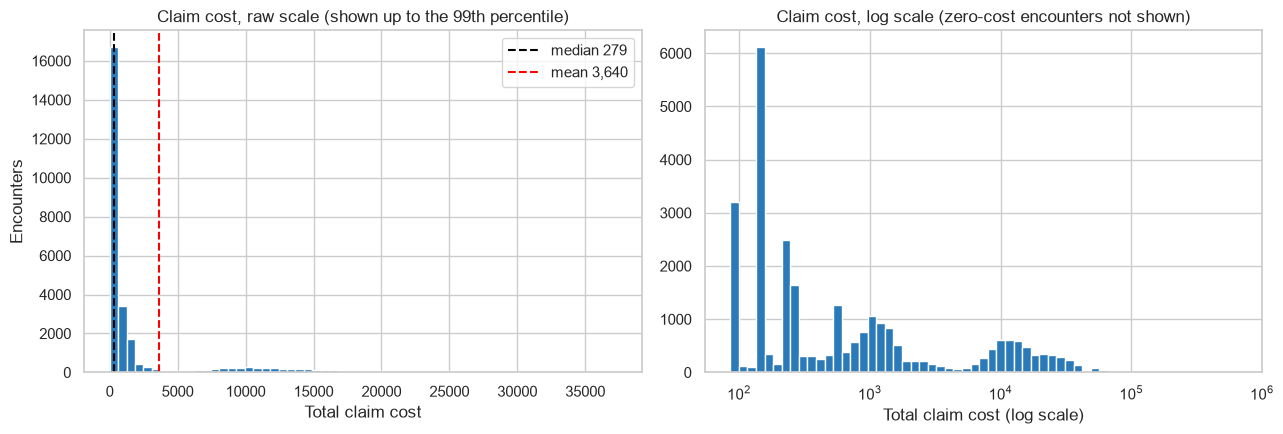

In [10]:
from scipy import stats

FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

cost = enc["total_claim_cost"]
print(f"mean {cost.mean():,.2f} | median {cost.median():,.2f} | "
      f"skewness {stats.skew(cost):.2f} | kurtosis {stats.kurtosis(cost):.2f}")
print(cost.quantile([.5, .75, .9, .95, .99, .999]).round(2).to_string())
print("Share of encounters below the mean:", round((cost < cost.mean()).mean() * 100, 1), "%")
print("Zero-cost encounters:", (cost == 0).sum())
print("Maximum is", round(cost.max() / cost.median()), "times the median")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: raw scale, cut at the 99th percentile so the bars are visible
ax[0].hist(cost[cost <= cost.quantile(.99)], bins=60, color="#2a7ab9")
ax[0].axvline(cost.median(), color="black", ls="--", label=f"median {cost.median():,.0f}")
ax[0].axvline(cost.mean(), color="red", ls="--", label=f"mean {cost.mean():,.0f}")
ax[0].set_title("Claim cost, raw scale (shown up to the 99th percentile)")
ax[0].set_xlabel("Total claim cost")
ax[0].set_ylabel("Encounters")
ax[0].legend()

# Right: log scale, so the whole range can be seen
pos = cost[cost > 0]
ax[1].hist(pos, bins=np.logspace(np.log10(pos.min()), np.log10(pos.max()), 60), color="#2a7ab9")
ax[1].set_xscale("log")
ax[1].set_title("Claim cost, log scale (zero-cost encounters not shown)")
ax[1].set_xlabel("Total claim cost (log scale)")

plt.tight_layout()
plt.savefig(FIG / "fig01_claim_cost_distribution.png", dpi=150)
plt.show()